# Dataset readiness — shape-based analysis project

Datasets: atomically resolved BiFeO₃ images and ferroelectric domain images (Richard).

1. Inventory of candidate files in the project folder
2. Readability checks
3. Overview of the ferroelectric domain images
4. Domain segmentation and wall metrics (written domains)
5. Natural domain walls and stripe domains (raw Igor frames)
6. BiFeO₃ atomic-column / polarization pipeline (validated on synthetic data; runs on the real files once they are in `richard/BFO_STEM/`)
7. Status summary

Requirements: `numpy scipy scikit-image matplotlib pandas igor2`; optional `hyperspy` for `.dm3/.dm4/.emd`.


In [1]:
import os, sys, re, json, zipfile, hashlib, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi, optimize, special
from skimage import measure, morphology, filters, feature, segmentation
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 100, 'image.interpolation': 'nearest', 'axes.titlesize': 9})

try:
    import igor2.binarywave as ibw_reader
    HAVE_IGOR = True
except ImportError:
    HAVE_IGOR = False
    print('igor2 not installed -> pip install igor2  (needed for the raw .ibw scans)')
print('numpy', np.__version__, '| igor2:', HAVE_IGOR)

numpy 2.5.3 | igor2: True


## 1. Folders and inventory

Paths are relative to the project folder `Trajectory Litho Scan-Newsha's Project` (override with the `NEWSHA_PROJECT_DIR` environment variable).

In [2]:
def find_project_dir():
    env = os.environ.get('NEWSHA_PROJECT_DIR')
    if env and Path(env).exists():
        return Path(env)
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / 'Colab_Data_Access').exists() or (p / 'richard').exists():
            return p
    raise FileNotFoundError('Set NEWSHA_PROJECT_DIR to the "Trajectory Litho Scan-Newsha\'s Project" folder')

PROJECT_DIR = find_project_dir()
BOX_DIR     = PROJECT_DIR.parent                      # Box root that also holds the "Newsha" folder
NEWSHA_DIR  = BOX_DIR / 'Newsha'
NB_DIR      = PROJECT_DIR / 'Shape_Based_Dataset_Prep'
DATA_DIR    = NB_DIR / 'data'                         # extracted copy of Richard's collection (created on first run)
OUT_DIR     = NB_DIR / 'outputs'
for d in (DATA_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLLECTION_ZIP = PROJECT_DIR / 'Colab_Data_Access' / 'Richard_PZT_PFM_Collection_v1.zip'
RAW_RICHARD    = PROJECT_DIR / 'richard' / 'MOBO DKL'
BFO_DIR        = PROJECT_DIR / 'richard' / 'BFO_STEM'  # BiFeO3 STEM files

print('PROJECT_DIR :', PROJECT_DIR)
print('NEWSHA_DIR  :', NEWSHA_DIR, '(exists)' if NEWSHA_DIR.exists() else '(not found)')
print('collection  :', COLLECTION_ZIP.name, 'found' if COLLECTION_ZIP.exists() else 'MISSING')
print('raw richard :', RAW_RICHARD, 'found' if RAW_RICHARD.exists() else 'MISSING')

PROJECT_DIR : /tmp/claude-0/-home-claude/b3624841-060d-5cac-8a83-d0b438c324e3/scratchpad/box/Trajectory Litho Scan-Newsha's Project
NEWSHA_DIR  : /tmp/claude-0/-home-claude/b3624841-060d-5cac-8a83-d0b438c324e3/scratchpad/box/Newsha (exists)
collection  : Richard_PZT_PFM_Collection_v1.zip found
raw richard : /tmp/claude-0/-home-claude/b3624841-060d-5cac-8a83-d0b438c324e3/scratchpad/box/Trajectory Litho Scan-Newsha's Project/richard/MOBO DKL found


### 1.1 Richard's PFM collection (ferroelectric domain images)

`Colab_Data_Access/Richard_PZT_PFM_Collection_v1.zip` — lossless repackaging of the eight MOBO-DKL sessions in `richard/MOBO DKL/processed/*.pickle`; extracted once into `Shape_Based_Dataset_Prep/data/`.

In [3]:
COLL = DATA_DIR / 'Richard_PZT_PFM_Collection'
if not (COLL / 'manifest.json').exists():
    assert COLLECTION_ZIP.exists(), f'{COLLECTION_ZIP} not found - sync Box or copy the zip here'
    with zipfile.ZipFile(COLLECTION_ZIP) as z:
        z.extractall(DATA_DIR)
    print('extracted', COLLECTION_ZIP.name, '->', COLL)
else:
    print('using already-extracted collection at', COLL)

manifest = pd.DataFrame(json.load(open(COLL / 'manifest.json')))
SESSIONS = sorted(p.stem for p in (COLL / 'sessions').glob('*.npz'))
manifest[['session','material','date','n_writes','scan_size_um','scan_points','patch_px','dkl_window','empty_traces','core_MB','dkl_MB']]

using already-extracted collection at /tmp/claude-0/-home-claude/b3624841-060d-5cac-8a83-d0b438c324e3/scratchpad/box/Trajectory Litho Scan-Newsha's Project/Shape_Based_Dataset_Prep/data/Richard_PZT_PFM_Collection


,session,material,date,n_writes,scan_size_um,scan_points,patch_px,dkl_window,empty_traces,core_MB,dkl_MB
0,20250502_PTKTO_DW1,PTKTO,2025-05-02,105,5.0,128,64,16,44,7.5,3.6
1,20250507_PTKTO_DW1,PTKTO,2025-05-07,105,5.0,128,64,8,30,7.0,0.6
2,20250508_PTKTO_DW3,PTKTO,2025-05-08,105,5.0,128,64,8,35,6.9,0.6
3,20250509_PTKTO_DW3,PTKTO,2025-05-09,110,5.0,128,64,8,47,9.5,3.4
4,20250509_PTKTO_DW4,PTKTO,2025-05-09,110,5.0,128,64,8,39,9.6,3.6
5,20250509_PTKTO_DW5,PTKTO,2025-05-10,210,10.0,256,64,8,55,17.8,8.0
6,20250514_PZTO_DW1,PZTO,2025-05-14,110,5.0,128,64,8,20,6.6,0.5
7,20250522_PTKTO_DW4,PTKTO,2025-05-23,210,10.0,256,64,16,52,17.9,25.4


### 1.2 Inventory of candidate files

Search of the project folder and the `Newsha` folder for PFM data and for STEM files (`.dm3/.dm4/.emd/.h5/.ser/.tif/.npy`, or names containing BFO / BiFeO / bismuth / HAADF / STEM / atom).

In [4]:
STEM_EXT  = {'.dm3', '.dm4', '.emd', '.h5', '.hdf5', '.ser', '.mrc', '.tif', '.tiff', '.npy'}
STEM_NAME = re.compile(r'bfo|bifeo|bismuth|haadf|stem|atom', re.I)
SKIP_DIRS = {'.venv', '__pycache__', '.git', 'node_modules', '_to_delete', 'site-packages', '.jupyter'}

def walk(root, max_files=200000):
    rows = []
    if not root.exists():
        return rows
    for dp, dns, fns in os.walk(root):
        dns[:] = [d for d in dns if d not in SKIP_DIRS]
        for f in fns:
            p = Path(dp) / f
            try:
                rows.append((p, p.stat().st_size))
            except OSError:
                pass
            if len(rows) > max_files:
                return rows
    return rows

inventory = []
for root in (PROJECT_DIR, NEWSHA_DIR):
    for p, sz in walk(root):
        ext = p.suffix.lower()
        kind = None
        if ext == '.ibw':                                    kind = 'Igor PFM scan (.ibw)'
        elif ext == '.pickle' and 'MOBO DKL' in str(p):      kind = 'MOBO-DKL session (pickle)'
        elif ext == '.npz' and 'sessions' in p.parts:        kind = 'MOBO-DKL session (npz)'
        elif ext == '.npz' and 'dkl_state' in p.parts:       kind = 'DKL state (npz)'
        elif ext in STEM_EXT or STEM_NAME.search(p.name):    kind = 'candidate STEM / atomic-resolution'
        if kind:
            inventory.append(dict(kind=kind, file=str(p.relative_to(BOX_DIR)), MB=round(sz/1e6, 2)))
inventory = pd.DataFrame(inventory)
print(inventory.groupby('kind').agg(n=('file','size'), MB=('MB','sum')).round(1))
print()
stem_cands = inventory[inventory.kind.str.startswith('candidate STEM')]
if len(stem_cands):
    print('Candidate STEM/atomic-resolution files (check these by eye):')
    display(stem_cands.sort_values('MB', ascending=False).head(40))
else:
    print('No STEM / atomic-resolution candidates found anywhere in the two Box folders.')

                                     n    MB
kind                                        
DKL state (npz)                      8  45.7
Igor PFM scan (.ibw)                20  25.7
MOBO-DKL session (npz)               8  82.9
candidate STEM / atomic-resolution   1   0.4

Candidate STEM/atomic-resolution files (check these by eye):


,kind,file,MB
0,candidate STEM / atomic-resolution,Trajectory Litho Scan-Newsha's Project/Shape_B...,0.35


## 2. Readability checks

In [5]:
def load_session(name):
    d = np.load(COLL / 'sessions' / f'{name}.npz')
    s = {k: d[k] for k in d.files if k not in ('header_json', 'meta_json')}
    s['header'] = json.loads(str(d['header_json']))
    s['meta']   = json.loads(str(d['meta_json']))
    o = np.r_[0, np.cumsum(s['trace_len'])]
    s['traces'] = [(s['trace_x'][o[i]:o[i+1]], s['trace_y'][o[i]:o[i+1]]) for i in range(len(s['trace_len']))]
    return s

def load_ibw(path):
    w = ibw_reader.load(str(path))['wave']
    data = np.asarray(w['wData'])
    note = w['note'].decode('latin1', 'replace') if isinstance(w['note'], bytes) else str(w['note'])
    hdr = {}
    for line in re.split(r'[\r\n]+', note):
        if ':' in line:
            k, v = line.split(':', 1); hdr[k.strip()] = v.strip()
    labels = [l.decode('latin1', 'replace') if isinstance(l, bytes) else l for l in w['labels'][2]] if len(w['labels']) > 2 else []
    labels = [l for l in labels if l]
    chans = {lab: data[..., i].T for i, lab in enumerate(labels)}   # transpose -> (rows, cols) with slow axis first
    return chans, hdr

checks = []
# -- sessions
for name in SESSIONS:
    try:
        s = load_session(name)
        n = len(s['trace_len'])
        ok = (s['amp_before'].shape == s['amp_after'].shape == s['phase_before'].shape == s['phase_after'].shape == (n, 64, 64)
              and s['coords'].shape == (n, 2) and np.isfinite(s['phase_after']).all())
        checks.append(dict(dataset='MOBO-DKL session', file=f'sessions/{name}.npz', material=s['meta']['material'],
                           shape=f"{n}x64x64 (before/after amp+phase)", scan=f"{s['header']['ScanSize']*1e6:.0f} um / {s['topo'].shape[0]} px global",
                           extra=f"window {s['meta']['ws']} px, {int((s['trace_len']==0).sum())} empty traces", readable=bool(ok)))
    except Exception as e:
        checks.append(dict(dataset='MOBO-DKL session', file=name, readable=False, extra=repr(e)))
# -- raw Igor frames (Richard's three + the 14 PZTO(111) litho frames)
ibw_files = sorted(RAW_RICHARD.glob('*.ibw')) + sorted((COLL / 'pzto111_litho_frames').glob('*.ibw'))
for p in ibw_files:
    try:
        ch, hdr = load_ibw(p)
        a = next(iter(ch.values()))
        checks.append(dict(dataset='Igor PFM frame', file=str(p.relative_to(PROJECT_DIR)) if PROJECT_DIR in p.parents else p.name,
                           material='PTKTO' if 'PTKTO' in p.name else 'PZTO', shape=f"{a.shape[0]}x{a.shape[1]} x {len(ch)} ch",
                           scan=f"{float(hdr.get('ScanSize', 'nan'))*1e6:.1f} um", extra=f"{hdr.get('ImagingMode','?')}, {hdr.get('Date','?')}",
                           readable=all(np.isfinite(v).all() for v in ch.values())))
    except Exception as e:
        checks.append(dict(dataset='Igor PFM frame', file=p.name, readable=False, extra=repr(e)))
# -- reward maps
for p in sorted(RAW_RICHARD.glob('mobo_dkl_data*.npz')):
    try:
        d = np.load(p); checks.append(dict(dataset='MOBO reward maps', file=p.name, shape=', '.join(f'{k}{d[k].shape}' for k in d.files), readable=True))
    except Exception as e:
        checks.append(dict(dataset='MOBO reward maps', file=p.name, readable=False, extra=repr(e)))
# -- BFO
bfo_files = sorted(p for p in BFO_DIR.glob('**/*') if p.suffix.lower() in STEM_EXT) if BFO_DIR.exists() else []
checks.append(dict(dataset='BiFeO3 atomic-resolution (STEM)', file=str(BFO_DIR.relative_to(PROJECT_DIR)) + '/*',
                   shape=f'{len(bfo_files)} files', readable=bool(bfo_files), extra='no files' if not bfo_files else ''))

readiness = pd.DataFrame(checks)
readiness.to_csv(OUT_DIR / 'readiness_table.csv', index=False)
print(f"{readiness.readable.sum()} / {len(readiness)} entries readable")
readiness

27 / 28 entries readable


,dataset,file,material,shape,scan,extra,readable
0,MOBO-DKL session,sessions/20250502_PTKTO_DW1.npz,PTKTO,105x64x64 (before/after amp+phase),5 um / 128 px global,"window 16 px, 44 empty traces",True
1,MOBO-DKL session,sessions/20250507_PTKTO_DW1.npz,PTKTO,105x64x64 (before/after amp+phase),5 um / 128 px global,"window 8 px, 30 empty traces",True
2,MOBO-DKL session,sessions/20250508_PTKTO_DW3.npz,PTKTO,105x64x64 (before/after amp+phase),5 um / 128 px global,"window 8 px, 35 empty traces",True
3,MOBO-DKL session,sessions/20250509_PTKTO_DW3.npz,PTKTO,110x64x64 (before/after amp+phase),5 um / 128 px global,"window 8 px, 47 empty traces",True
4,MOBO-DKL session,sessions/20250509_PTKTO_DW4.npz,PTKTO,110x64x64 (before/after amp+phase),5 um / 128 px global,"window 8 px, 39 empty traces",True
5,MOBO-DKL session,sessions/20250509_PTKTO_DW5.npz,PTKTO,210x64x64 (before/after amp+phase),10 um / 256 px global,"window 8 px, 55 empty traces",True
6,MOBO-DKL session,sessions/20250514_PZTO_DW1.npz,PZTO,110x64x64 (before/after amp+phase),5 um / 128 px global,"window 8 px, 20 empty traces",True
7,MOBO-DKL session,sessions/20250522_PTKTO_DW4.npz,PTKTO,210x64x64 (before/after amp+phase),10 um / 256 px global,"window 16 px, 52 empty traces",True
8,Igor PFM frame,richard/MOBO DKL/PTKTO_training_0462.ibw,PTKTO,64x64 x 6 ch,1.0 um,"PFM Mode, 2025-05-22",True
9,Igor PFM frame,richard/MOBO DKL/PTKTO_training_0464.ibw,PTKTO,64x64 x 6 ch,1.0 um,"PFM Mode, 2025-05-22",True


## 3. Overview of the ferroelectric domain images

Per session: one global 5 or 10 µm PFM scan (topography + phase) with the write locations, and for every write a 64×64 PFM patch (amplitude + phase) before and after writing.

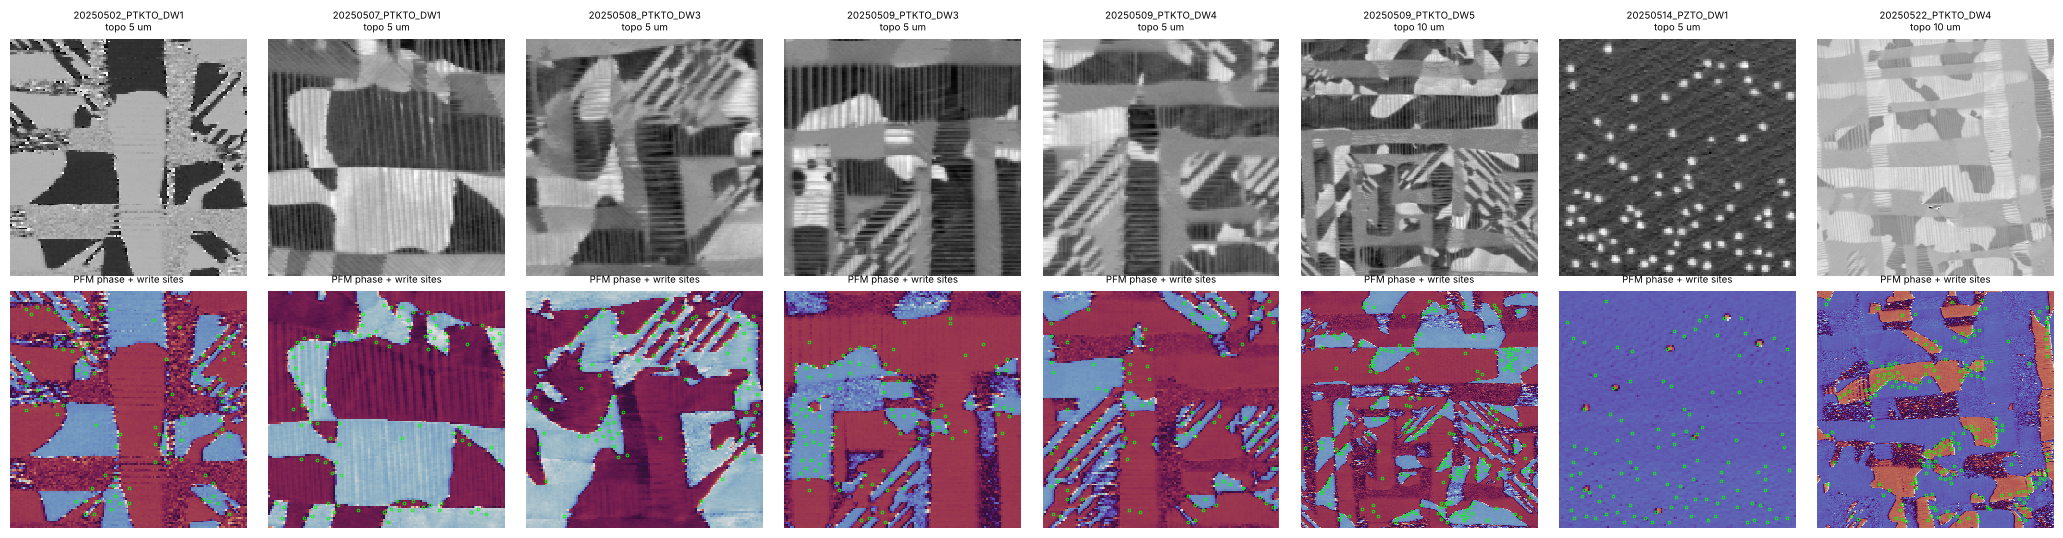

In [6]:
fig, axes = plt.subplots(2, len(SESSIONS), figsize=(2.6*len(SESSIONS), 5.4))
for j, name in enumerate(SESSIONS):
    s = load_session(name)
    axes[0, j].imshow(s['topo'], cmap='gray'); axes[0, j].set_title(f"{name}\ntopo {s['header']['ScanSize']*1e6:.0f} um", fontsize=7)
    axes[1, j].imshow(s['phase'], cmap='twilight'); axes[1, j].set_title('PFM phase + write sites', fontsize=7)
    axes[1, j].plot(s['coords'][:, 1], s['coords'][:, 0], 'o', ms=2, mfc='none', mec='lime', mew=0.6)
    for a in axes[:, j]: a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig_global_scans.png', dpi=130); plt.show()

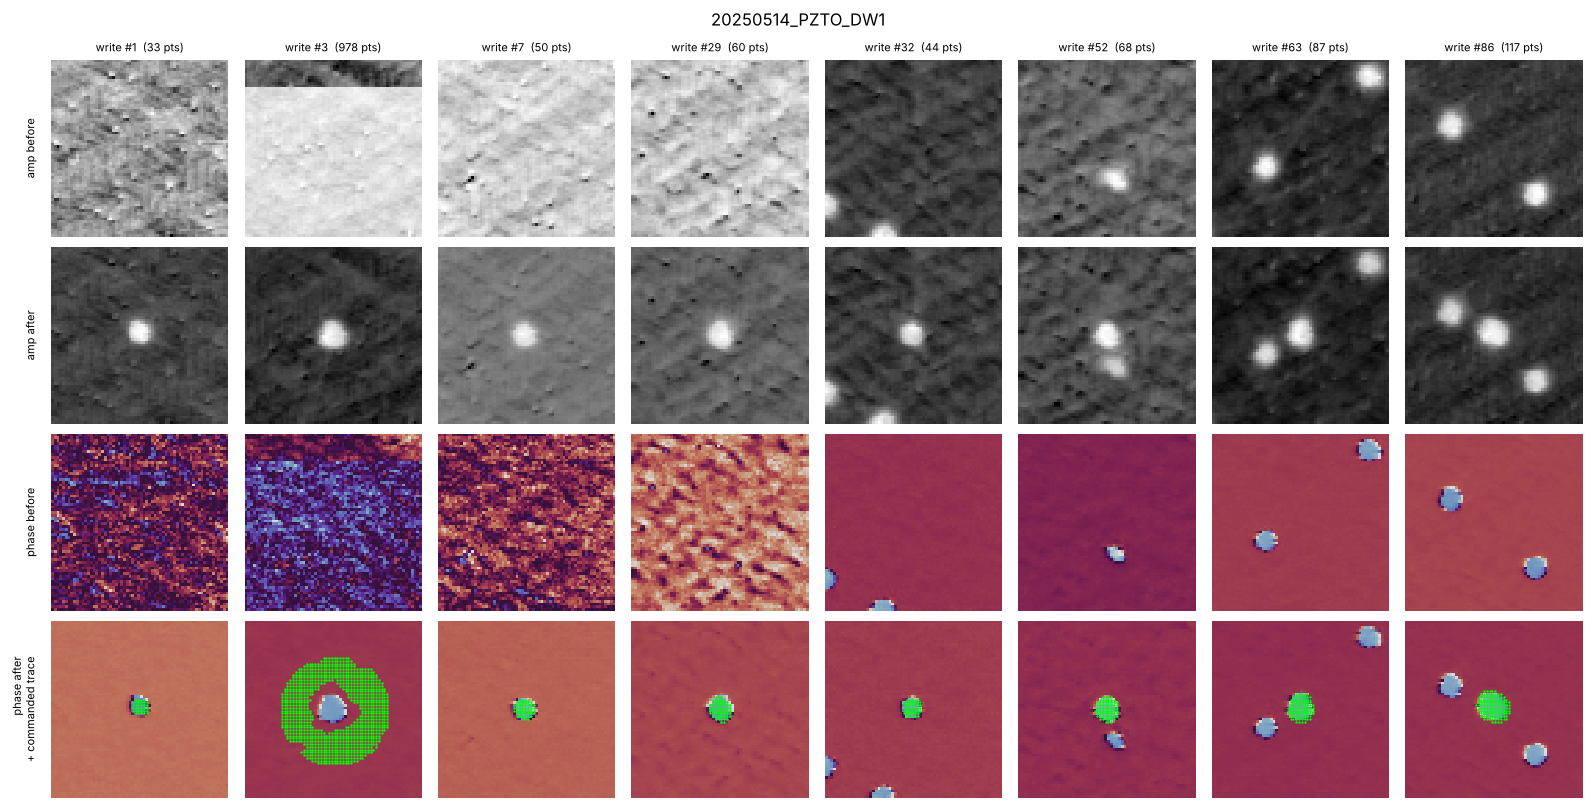

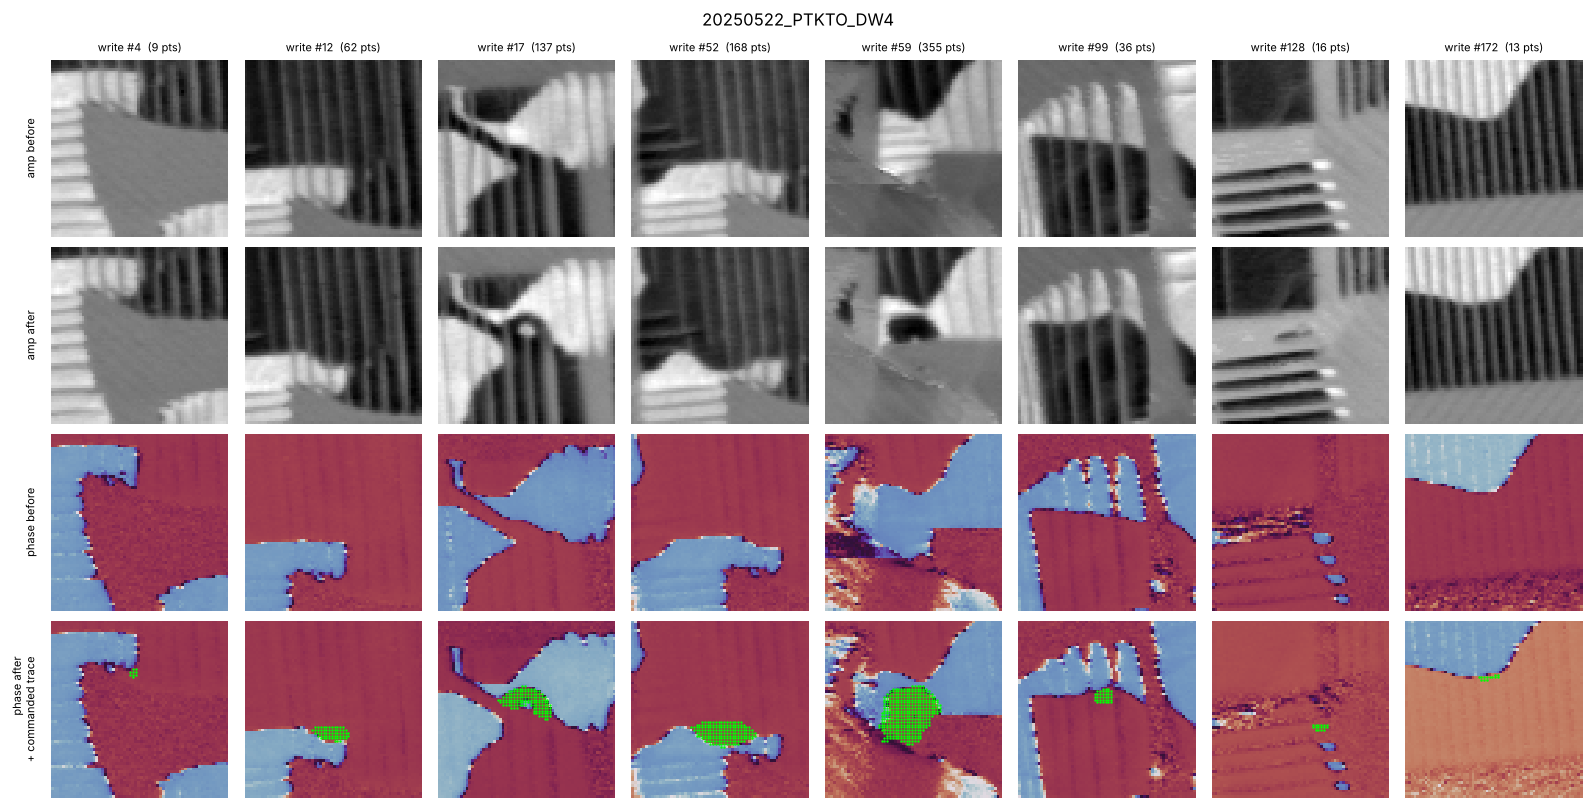

In [7]:
def show_writes(name, n=8, seed=0):
    s = load_session(name)
    idx = [i for i in range(len(s['trace_len'])) if s['trace_len'][i] > 0]
    rng = np.random.default_rng(seed); idx = sorted(rng.choice(idx, min(n, len(idx)), replace=False))
    fig, ax = plt.subplots(4, len(idx), figsize=(2*len(idx), 8.2))
    for j, i in enumerate(idx):
        for r, (k, cm) in enumerate([('amp_before','gray'), ('amp_after','gray'), ('phase_before','twilight'), ('phase_after','twilight')]):
            ax[r, j].imshow(s[k][i], cmap=cm); ax[r, j].axis('off')
        tx, ty = s['traces'][i]
        ax[3, j].plot(tx, ty, '.', ms=1.5, color='lime')
        ax[0, j].set_title(f'write #{i}  ({len(tx)} pts)', fontsize=8)
    for r, lab in enumerate(['amp before', 'amp after', 'phase before', 'phase after\n+ commanded trace']):
        ax[r, 0].text(-0.08, 0.5, lab, transform=ax[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8)
    fig.suptitle(name); plt.tight_layout(); plt.savefig(OUT_DIR / f'fig_writes_{name}.png', dpi=130); plt.show()

show_writes('20250514_PZTO_DW1')
show_writes('20250522_PTKTO_DW4')

## 4. Domain segmentation and wall metrics (written domains)

Mask: $|\mathrm{wrap}(\varphi_{after}-\varphi_{before})| > 90^\circ$, morphological opening/closing, keep the component that overlaps the commanded trace (largest component if the trace is empty).
Metrics per write: area, equivalent diameter, wall length (Crofton perimeter), circularity $4\pi A/P^2$, aspect ratio and orientation (ellipse fit), wall width (FWHM of an erf step fitted to radial $|\Delta\varphi|$ profiles, median over 24 angles), IoU with the dilated trace footprint, amplitude-after contrast inside the mask.
Units: pixels. The 64×64 patch scan size is not stored in the collection; the raw frames `PTKTO_training_0462/0464.ibw` from the same session are 1 µm / 64 px.

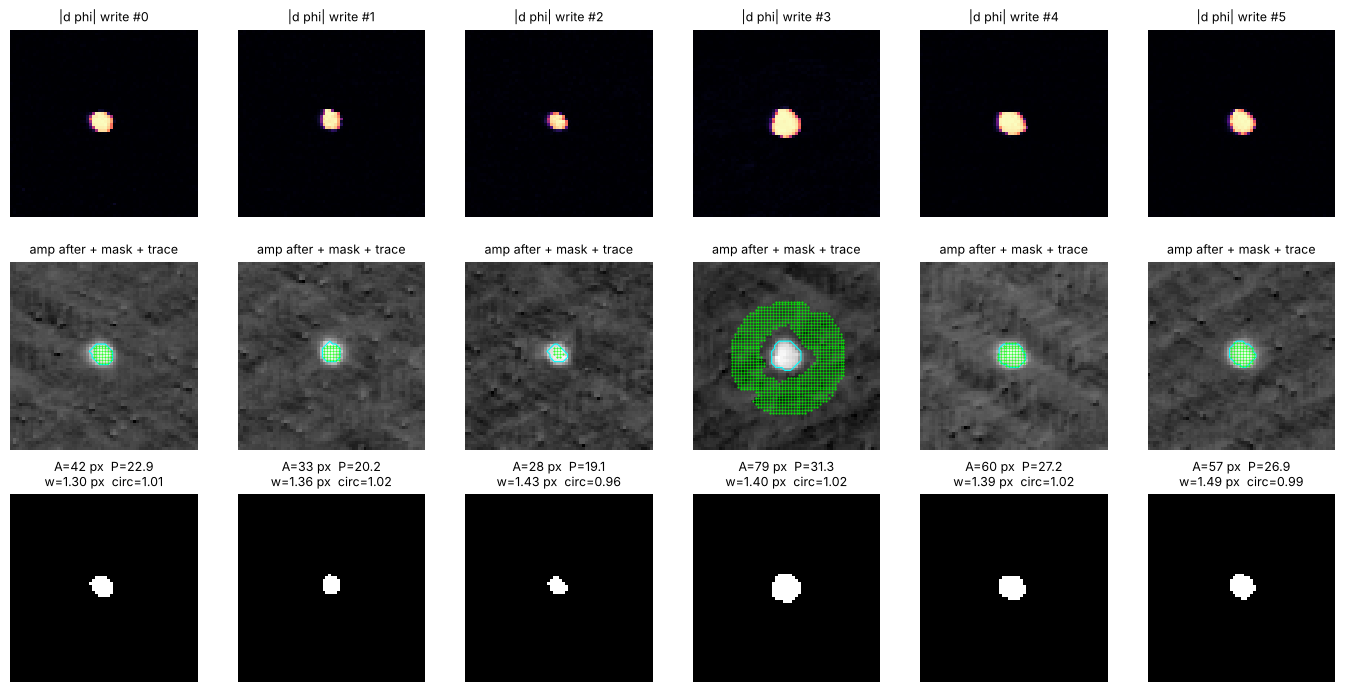

In [8]:
def wrap_deg(x):
    return (x + 180.0) % 360.0 - 180.0

def segment_domain(phase_before, phase_after, trace=None, thr=90.0, min_size=4):
    dphi = np.abs(wrap_deg(phase_after.astype(float) - phase_before.astype(float)))
    m = dphi > thr
    m = morphology.binary_opening(m, morphology.disk(1))
    m = morphology.binary_closing(m, morphology.disk(1))
    m = morphology.remove_small_objects(m, min_size)
    lab = measure.label(m)
    if lab.max() == 0:
        return np.zeros_like(m), dphi
    if trace is not None and len(trace[0]):
        tx, ty = np.clip(trace[0], 0, 63), np.clip(trace[1], 0, 63)
        hits = np.bincount(lab[ty, tx], minlength=lab.max()+1); hits[0] = 0
        keep = hits.argmax() if hits.max() > 0 else None
    else:
        keep = None
    if keep is None:
        keep = np.bincount(lab.ravel())[1:].argmax() + 1
    return lab == keep, dphi

def erf_step(r, A, r0, sig, b):
    return b + 0.5*A*(1 + special.erf((r0 - r)/(np.sqrt(2)*sig)))

def wall_width(dphi, mask, n_angles=24):
    if mask.sum() < 4:
        return np.nan
    cy, cx = ndi.center_of_mass(mask)
    rmax = min(cy, cx, 63-cy, 63-cx, 3*np.sqrt(mask.sum()/np.pi) + 4)
    r = np.linspace(0, rmax, int(rmax*4)+1)
    widths = []
    for th in np.linspace(0, 2*np.pi, n_angles, endpoint=False):
        prof = ndi.map_coordinates(dphi, [cy + r*np.sin(th), cx + r*np.cos(th)], order=1, mode='nearest')
        try:
            (A, r0, sig, b), _ = optimize.curve_fit(erf_step, r, prof, p0=[prof.max()-prof.min(), np.sqrt(mask.sum()/np.pi), 1.0, prof.min()],
                                                   bounds=([0, 0, 0.2, -10], [400, rmax, 10, 400]), maxfev=2000)
            if A > 60: widths.append(2.355*sig)
        except Exception:
            pass
    return float(np.median(widths)) if widths else np.nan

def trace_footprint(trace, shape=(64, 64), dilate=1):
    f = np.zeros(shape, bool)
    if len(trace[0]):
        f[np.clip(trace[1], 0, 63), np.clip(trace[0], 0, 63)] = True
        f = morphology.binary_dilation(f, morphology.disk(dilate))
    return f

def domain_metrics(s, i):
    mask, dphi = segment_domain(s['phase_before'][i], s['phase_after'][i], s['traces'][i])
    row = dict(write=i, trace_pts=int(s['trace_len'][i]), area_px=int(mask.sum()))
    if mask.sum() == 0:
        return row, mask, dphi
    rp = measure.regionprops(mask.astype(int))[0]
    P = measure.perimeter_crofton(mask, directions=4)
    foot = trace_footprint(s['traces'][i])
    amp_after = s['amp_after'][i]; amp_z = (amp_after - np.median(amp_after)) / (1.4826*np.median(np.abs(amp_after - np.median(amp_after))) + 1e-9)
    row.update(eq_diam_px=rp.equivalent_diameter_area, wall_len_px=P, circularity=4*np.pi*mask.sum()/max(P, 1e-9)**2,
               aspect=rp.major_axis_length/max(rp.minor_axis_length, 1e-9), orient_deg=np.degrees(rp.orientation),
               wall_width_px=wall_width(dphi, mask),
               iou_trace=(mask & foot).sum()/max((mask | foot).sum(), 1) if foot.any() else np.nan,
               amp_contrast_z=float(np.median(amp_z[mask])), cy=rp.centroid[0], cx=rp.centroid[1])
    return row, mask, dphi

# demo on a few writes
s = load_session('20250514_PZTO_DW1')
demo = [i for i in range(len(s['trace_len'])) if s['trace_len'][i] > 0][:6]
fig, ax = plt.subplots(3, len(demo), figsize=(2.3*len(demo), 7))
for j, i in enumerate(demo):
    row, mask, dphi = domain_metrics(s, i)
    ax[0, j].imshow(dphi, cmap='magma', vmin=0, vmax=180); ax[0, j].set_title(f"|d phi| write #{i}")
    ax[1, j].imshow(s['amp_after'][i], cmap='gray'); ax[1, j].contour(mask, [0.5], colors='cyan', linewidths=0.8)
    ax[1, j].plot(*s['traces'][i], '.', ms=1, color='lime'); ax[1, j].set_title('amp after + mask + trace')
    ax[2, j].imshow(mask, cmap='gray'); ax[2, j].set_title(f"A={row['area_px']} px  P={row['wall_len_px']:.1f}\nw={row['wall_width_px']:.2f} px  circ={row['circularity']:.2f}")
    for a in ax[:, j]: a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig_segmentation_demo.png', dpi=130); plt.show()

### 4.1 All writes

In [9]:
rows = []
for name in SESSIONS:
    s = load_session(name)
    for i in range(len(s['trace_len'])):
        row, _, _ = domain_metrics(s, i)
        row.update(session=name, material=s['meta']['material']); rows.append(row)
dom = pd.DataFrame(rows)
dom['segmented'] = dom.area_px > 0
dom.to_csv(OUT_DIR / 'domain_metrics_all_writes.csv', index=False)

summary = (dom.groupby('session')
           .agg(material=('material','first'), writes=('write','size'), with_trace=('trace_pts', lambda x: int((x>0).sum())),
                segmented=('segmented','sum'), area_px=('area_px', lambda x: f"{x[x>0].median():.0f} [{x[x>0].quantile(.25):.0f}-{x[x>0].quantile(.75):.0f}]"),
                wall_len_px=('wall_len_px','median'), wall_width_px=('wall_width_px','median'), circularity=('circularity','median'),
                iou_trace=('iou_trace','median'), amp_contrast_z=('amp_contrast_z','median'))
           .round(2))
summary.to_csv(OUT_DIR / 'domain_metrics_per_session.csv')
print(f"segmented a written domain in {dom.segmented.sum()} / {len(dom)} writes "
      f"({dom[dom.trace_pts>0].segmented.mean()*100:.0f}% of writes with a trace, {dom[dom.trace_pts==0].segmented.mean()*100:.0f}% of empty-trace writes)")
summary

segmented a written domain in 900 / 1065 writes (96% of writes with a trace, 58% of empty-trace writes)


,material,writes,with_trace,segmented,area_px,wall_len_px,wall_width_px,circularity,iou_trace,amp_contrast_z
session,,,,,,,,,,
20250502_PTKTO_DW1,PTKTO,105,61,83,44 [16-109],29.36,1.57,0.79,0.60,-0.36
20250507_PTKTO_DW1,PTKTO,105,75,88,79 [32-174],43.58,1.74,0.63,0.54,-0.05
20250508_PTKTO_DW3,PTKTO,105,70,95,118 [47-202],50.58,1.66,0.61,0.53,-0.15
20250509_PTKTO_DW3,PTKTO,110,63,93,87 [25-185],42.86,1.46,0.68,0.57,-0.35
20250509_PTKTO_DW4,PTKTO,110,71,96,68 [34-135],38.35,1.65,0.69,0.57,-0.06
20250509_PTKTO_DW5,PTKTO,210,155,190,126 [44-224],50.35,1.57,0.69,0.65,-0.31
20250514_PZTO_DW1,PZTO,110,90,89,59 [50-67],27.47,1.44,1.01,0.60,11.35
20250522_PTKTO_DW4,PTKTO,210,158,166,117 [41-214],48.07,1.48,0.75,0.60,-0.44


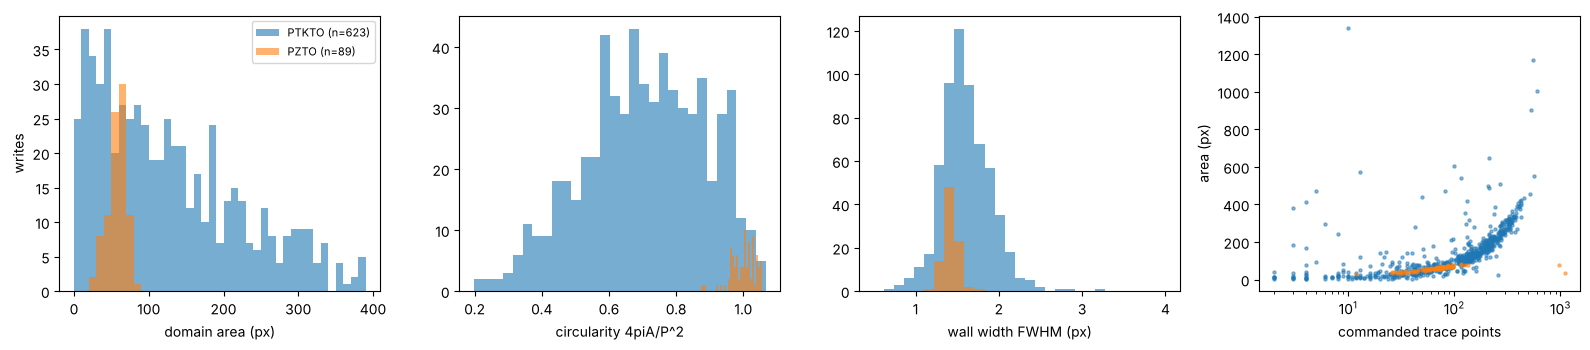

Correlation trace length vs written area: 0.66


In [10]:
d = dom[dom.segmented & (dom.trace_pts > 0)]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for mat, c in [('PTKTO', 'tab:blue'), ('PZTO', 'tab:orange')]:
    x = d[d.material == mat]
    ax[0].hist(x.area_px, bins=np.arange(0, 400, 10), alpha=.6, color=c, label=f'{mat} (n={len(x)})')
    ax[1].hist(x.circularity.clip(0, 1.2), bins=30, alpha=.6, color=c)
    ax[2].hist(x.wall_width_px.dropna(), bins=np.linspace(0.5, 4, 30), alpha=.6, color=c)
    ax[3].scatter(x.trace_pts, x.area_px, s=5, alpha=.5, color=c)
ax[0].set(xlabel='domain area (px)', ylabel='writes'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='circularity 4piA/P^2'); ax[2].set(xlabel='wall width FWHM (px)'); ax[3].set(xlabel='commanded trace points', ylabel='area (px)', xscale='log')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig_domain_stats.png', dpi=130); plt.show()
print('Correlation trace length vs written area:', round(d[['trace_pts','area_px']].corr().iloc[0,1], 2))

## 5. Natural domain walls and stripe domains (raw Igor frames)

`PTKTO_training_0462/0464.ibw` (1 µm): wrapped phase split by Otsu threshold; the wall is the boundary of the brighter phase level. Wall width = FWHM of an erf fit across the wall along the local normal (200 points); roughness = RMS deviation of the wall from its smoothed copy.
`PZTO_test_0008.ibw` (5 µm) and the 14 PZTO(111) LDART frames (4 µm): stripe orientation from the structure tensor, period from the first FFT peak.

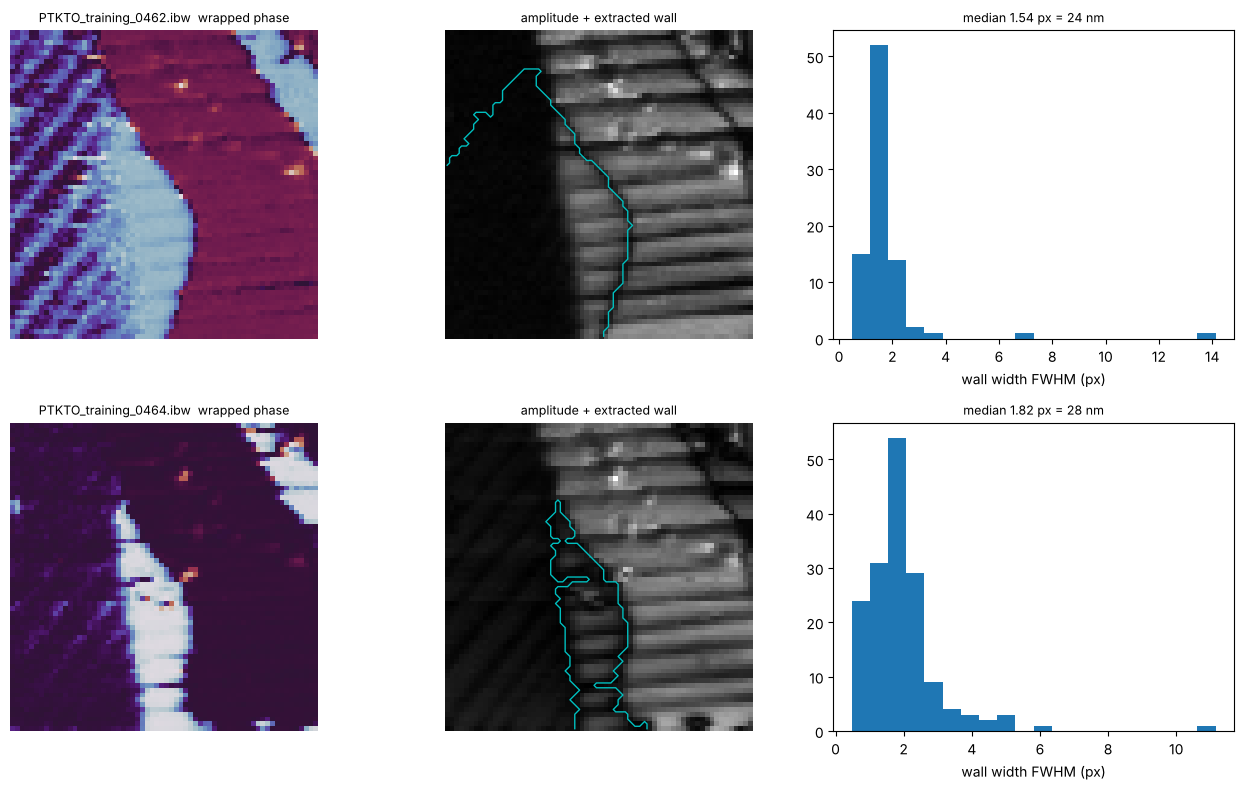

,file,nm_per_px,wall_length_px,wall_length_um,wall_width_px,wall_width_nm,roughness_px,up_fraction
0,PTKTO_training_0462.ibw,15.6,103.7,1.62,1.54,24.0,0.90,0.540
1,PTKTO_training_0464.ibw,15.6,149.2,2.33,1.82,28.4,1.25,0.866


In [11]:
def pick(ch, key):
    for k in ch:
        if key.lower() in k.lower(): return ch[k]
    raise KeyError(key)

def wall_from_phase(phase, min_region=50):
    # phase images of 180-degree walls are bimodal -> Otsu split on the wrapped phase
    ph = wrap_deg(phase - np.median(phase))
    t = filters.threshold_otsu(ph)
    m = ph > t
    m = morphology.remove_small_objects(m, min_region); m = morphology.remove_small_holes(m, min_region)
    return m, ph

def wall_profile_width(ph, m, n=200, L=6):
    # erf fit across the wall along the local normal at n random wall points
    cont = max(measure.find_contours(m.astype(float), 0.5), key=len)
    g = np.gradient(ndi.gaussian_filter(m.astype(float), 1.0))
    rng = np.random.default_rng(0); pts = cont[rng.choice(len(cont), min(n, len(cont)), replace=False)]
    t = np.linspace(-L, L, 4*L+1); w = []
    for (y, x) in pts:
        ny, nx = g[0][int(y), int(x)], g[1][int(y), int(x)]; nrm = np.hypot(ny, nx)
        if nrm < 1e-6: continue
        ny, nx = ny/nrm, nx/nrm
        prof = ndi.map_coordinates(ph, [y + t*ny, x + t*nx], order=1, mode='nearest')
        try:
            (A, r0, sig, b), _ = optimize.curve_fit(erf_step, -t, prof, p0=[prof.max()-prof.min(), 0, 1, prof.min()], bounds=([0, -L, .2, -400], [400, L, L, 400]), maxfev=2000)
            if A > 60: w.append(2.355*sig)
        except Exception: pass
    return cont, np.array(w)

wall_rows = []
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for j, p in enumerate(sorted(RAW_RICHARD.glob('PTKTO_training_*.ibw'))):
    ch, hdr = load_ibw(p); phase = pick(ch, 'Phase1'); amp = pick(ch, 'Amplitude1')
    nm_px = float(hdr['ScanSize'])*1e9/phase.shape[0]
    m, ph = wall_from_phase(phase)
    cont, w = wall_profile_width(ph, m)
    # roughness: deviation of the wall from its smoothed version
    sm = ndi.gaussian_filter1d(cont, 8, axis=0, mode='nearest'); rough = np.sqrt(((cont - sm)**2).sum(1)).mean()
    seg_len = np.hypot(*np.diff(cont, axis=0).T).sum()
    wall_rows.append(dict(file=p.name, nm_per_px=round(nm_px, 1), wall_length_px=round(seg_len, 1), wall_length_um=round(seg_len*nm_px/1e3, 2),
                          wall_width_px=round(np.median(w), 2), wall_width_nm=round(np.median(w)*nm_px, 1), roughness_px=round(rough, 2),
                          up_fraction=round(m.mean(), 3)))
    ax[j, 0].imshow(ph, cmap='twilight'); ax[j, 0].set_title(f'{p.name}  wrapped phase');
    ax[j, 1].imshow(amp, cmap='gray'); ax[j, 1].plot(cont[:, 1], cont[:, 0], 'c-', lw=1); ax[j, 1].set_title('amplitude + extracted wall')
    ax[j, 2].hist(w, bins=20, color='tab:blue'); ax[j, 2].set(xlabel='wall width FWHM (px)', title=f'median {np.median(w):.2f} px = {np.median(w)*nm_px:.0f} nm')
    for a in ax[j, :2]: a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig_natural_walls_PTKTO.png', dpi=130); plt.show()
walls = pd.DataFrame(wall_rows); walls.to_csv(OUT_DIR / 'natural_wall_metrics.csv', index=False); walls

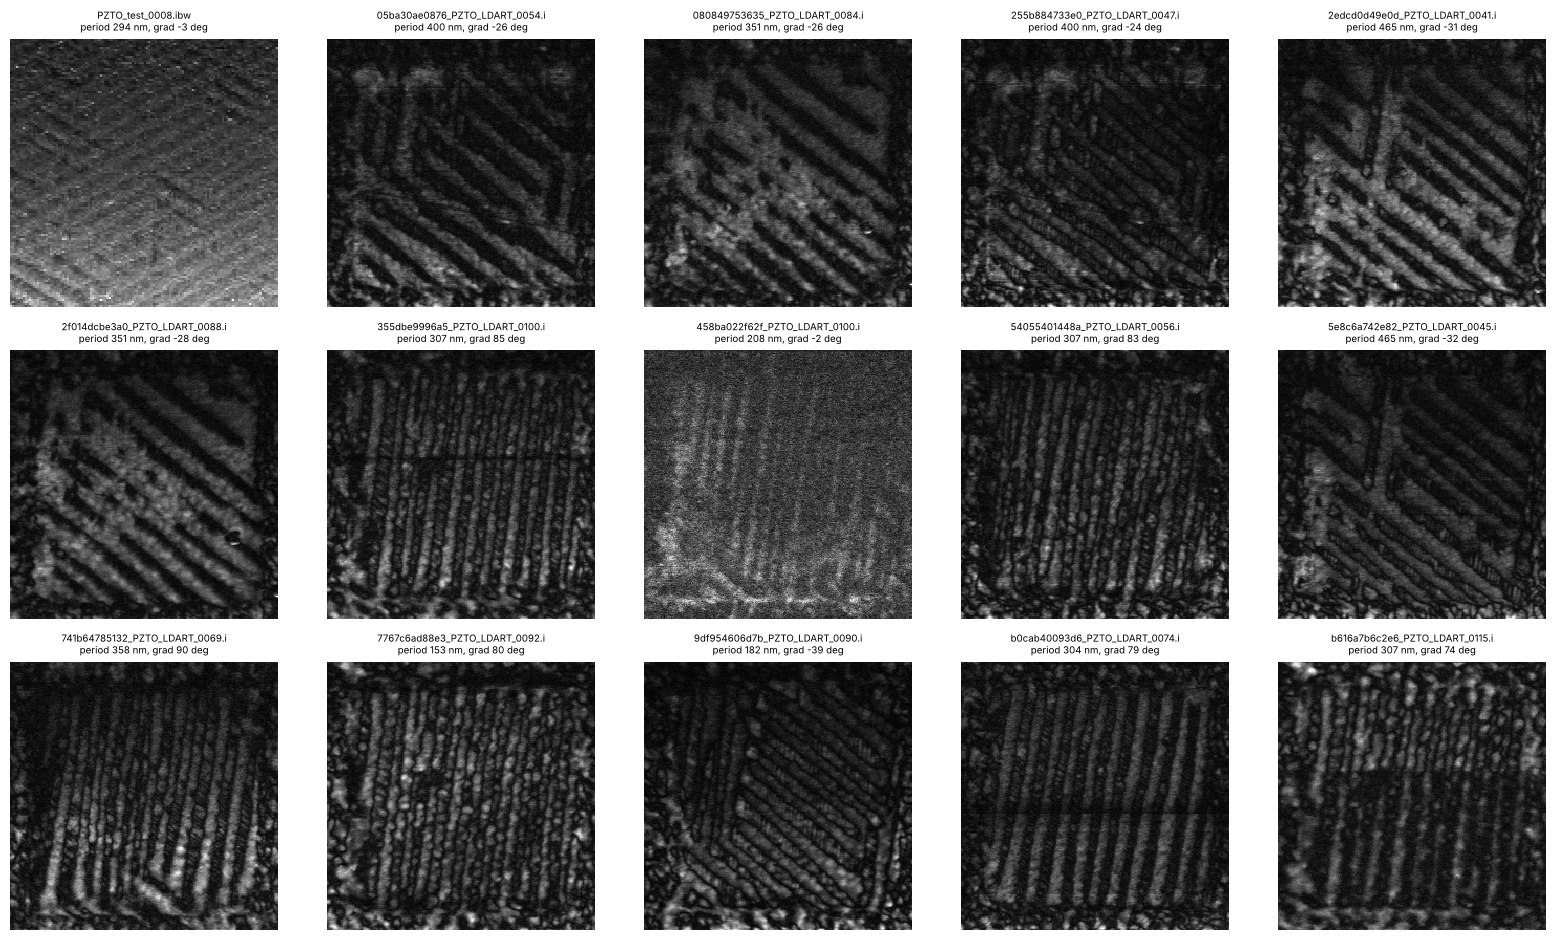

,file,size_um,px,gradient_orientation_deg,period_px,period_nm,date
0,PZTO_test_0008.ibw,5.0,128,-2.800000,7.5,294.0,2025-05-14
1,05ba30ae0876_PZTO_LDART_0054.ibw,4.0,256,-25.799999,25.6,400.0,2026-09-18
2,080849753635_PZTO_LDART_0084.ibw,4.0,256,-25.700001,22.5,351.0,2026-09-19
3,255b884733e0_PZTO_LDART_0047.ibw,4.0,256,-24.100000,25.6,400.0,2026-09-18
4,2edcd0d49e0d_PZTO_LDART_0041.ibw,4.0,256,-30.900000,29.8,465.0,2026-09-19
5,2f014dcbe3a0_PZTO_LDART_0088.ibw,4.0,256,-28.100000,22.5,351.0,2026-09-19
6,355dbe9996a5_PZTO_LDART_0100.ibw,4.0,256,85.199997,19.6,307.0,2026-09-18
7,458ba022f62f_PZTO_LDART_0100.ibw,4.0,256,-1.700000,13.3,208.0,2026-09-19
8,54055401448a_PZTO_LDART_0056.ibw,4.0,256,83.099998,19.6,307.0,2026-09-18
9,5e8c6a742e82_PZTO_LDART_0045.ibw,4.0,256,-32.200001,29.8,465.0,2026-09-19


In [12]:
# Stripe-domain orientation and period in the PZTO frames (5 um test frame + 14 PZTO(111) lithography frames)
def stripe_orientation(img, sigma=2):
    # structure tensor -> dominant orientation; radial FFT -> period
    im = (img - img.mean()) / (img.std() + 1e-9)
    Axx, Axy, Ayy = feature.structure_tensor(im, sigma=sigma, order='rc')
    theta = 0.5*np.degrees(np.arctan2(2*Axy.mean(), (Axx.mean() - Ayy.mean())))   # orientation of the gradient
    F = np.abs(np.fft.fftshift(np.fft.fft2(im*np.hanning(im.shape[0])[:, None]*np.hanning(im.shape[1])[None, :])))
    c = np.array(F.shape)//2; F[c[0]-2:c[0]+3, c[1]-2:c[1]+3] = 0
    ky, kx = np.unravel_index(F.argmax(), F.shape); k = np.hypot(ky-c[0], kx-c[1])
    return theta, (im.shape[0]/k if k > 0 else np.nan), F

frames = [RAW_RICHARD / 'PZTO_test_0008.ibw'] + sorted((COLL / 'pzto111_litho_frames').glob('*.ibw'))
stripe_rows = []; fig, ax = plt.subplots(3, 5, figsize=(16, 9.5))
for j, p in enumerate(frames):
    ch, hdr = load_ibw(p); amp = pick(ch, 'Amplitude1'); nm_px = float(hdr['ScanSize'])*1e9/amp.shape[0]
    th, per, F = stripe_orientation(amp)
    stripe_rows.append(dict(file=p.name, size_um=float(hdr['ScanSize'])*1e6, px=amp.shape[0], gradient_orientation_deg=round(th, 1), period_px=round(per, 1), period_nm=round(per*nm_px, 0), date=hdr.get('Date')))
    a = ax.flat[j]; a.imshow(amp, cmap='gray'); a.set_title(f"{p.name[:30]}\nperiod {per*nm_px:.0f} nm, grad {th:.0f} deg", fontsize=7); a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'fig_pzto_stripes.png', dpi=130); plt.show()
stripes = pd.DataFrame(stripe_rows); stripes.to_csv(OUT_DIR / 'pzto_stripe_metrics.csv', index=False); stripes

## 6. BiFeO₃ atomic-column and polarization pipeline

No BiFeO₃ STEM files are present in the Box folders (Section 1.2). The pipeline is validated on a synthetic HAADF image of BiFeO₃ along pseudocubic ⟨001⟩ with a known Fe displacement, and runs unchanged on real files placed in `richard/BFO_STEM/` (`.dm3 .dm4 .emd .h5 .tif .npy`).

Steps: Gaussian smoothing → `peak_local_max` → 2-D Gaussian refinement of each column (sub-pixel position, integrated intensity) → A (Bi) / B (Fe) sublattice split by intensity (2-means) → for each B column, displacement from the centroid of its four nearest A columns → $\mathbf{P} \propto -\boldsymbol{\delta}_{Fe}$ → quiver map and angle histogram.

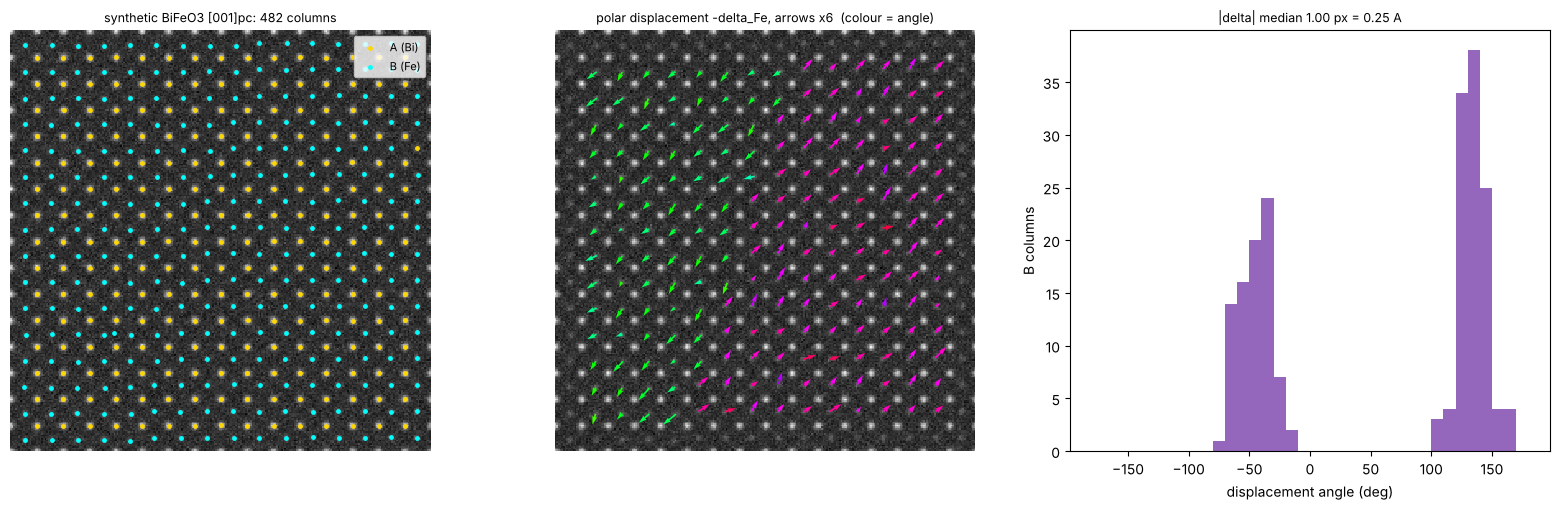

known |delta| = 1.00 px -> recovered median 1.00 px (MAD 0.21 px) from 196 B columns
known domain directions: -45 deg and +135 deg (delta_Fe along +[110] and -[110]); recovered: -45 deg x76, +135 deg x105


In [13]:
def gauss2d(coords, A, y0, x0, s, b):
    y, x = coords; return b + A*np.exp(-((y-y0)**2 + (x-x0)**2)/(2*s**2))

def find_atomic_columns(img, min_sep=4, sigma=0.8, thr_rel=0.05, win=None, refine=True):
    im = (img - img.min())/(img.max() - img.min() + 1e-12)
    ims = ndi.gaussian_filter(im, sigma)
    pk = feature.peak_local_max(ims, min_distance=min_sep, threshold_rel=thr_rel, exclude_border=min_sep)
    win = win or max(2, min_sep//2)
    out = []
    for (y, x) in pk:
        y0, y1, x0, x1 = max(0, y-win), min(im.shape[0], y+win+1), max(0, x-win), min(im.shape[1], x+win+1)
        patch = im[y0:y1, x0:x1]; yy, xx = np.mgrid[y0:y1, x0:x1]
        if refine:
            try:
                p, _ = optimize.curve_fit(gauss2d, (yy.ravel(), xx.ravel()), patch.ravel(),
                                          p0=[patch.max()-patch.min(), y, x, win/2, patch.min()],
                                          bounds=([0, y0, x0, 0.5, -1], [2, y1, x1, 2*win, 1]), maxfev=400)
                out.append((p[1], p[2], p[0]*2*np.pi*p[3]**2, p[3]))
                continue
            except Exception:
                pass
        w = patch - patch.min(); cy, cx = ndi.center_of_mass(w); out.append((y0+cy, x0+cx, w.sum(), np.nan))
    return pd.DataFrame(out, columns=['y', 'x', 'intensity', 'sigma'])

def split_sublattices(cols):
    # 2-means on log intensity: bright = A (Bi), dim = B (Fe)
    v = np.log(cols.intensity.clip(1e-6)).values; c = np.array([v.min(), v.max()])
    for _ in range(50):
        lab = np.abs(v[:, None]-c[None]).argmin(1); c = np.array([v[lab == k].mean() if (lab == k).any() else c[k] for k in (0, 1)])
    cols = cols.copy(); cols['site'] = np.where(lab == 1, 'A', 'B'); return cols

def polar_displacements(cols, a_px, tol=0.35):
    from scipy.spatial import cKDTree
    A = cols[cols.site == 'A'][['y', 'x']].values; B = cols[cols.site == 'B'][['y', 'x']].values
    tree = cKDTree(A); d, idx = tree.query(B, k=4)
    ok = (d.max(1) < a_px*(1/np.sqrt(2) + tol)) & (d.min(1) > a_px*(1/np.sqrt(2) - tol))   # four Bi corners at a/sqrt2
    cen = A[idx].mean(1); disp = B - cen
    out = pd.DataFrame(dict(y=B[:, 0], x=B[:, 1], dy=disp[:, 0], dx=disp[:, 1]))[ok].reset_index(drop=True)
    out['mag'] = np.hypot(out.dy, out.dx); out['angle_deg'] = np.degrees(np.arctan2(-out.dy, out.dx))   # image y points down -> flip
    return out

def analyze_haadf(img, a_px, title='', px_nm=None, save=None):
    # A-B distance is a/sqrt(2); a window of +-0.25a never reaches the neighbouring column's core
    cols = split_sublattices(find_atomic_columns(img, min_sep=max(3, int(round(a_px*0.25))), win=max(3, int(round(a_px*0.25)))))
    disp = polar_displacements(cols, a_px)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
    ax[0].imshow(img, cmap='gray'); ax[0].scatter(cols.x[cols.site=='A'], cols.y[cols.site=='A'], s=6, c='gold', label='A (Bi)')
    ax[0].scatter(cols.x[cols.site=='B'], cols.y[cols.site=='B'], s=6, c='cyan', label='B (Fe)'); ax[0].legend(fontsize=8, loc='upper right'); ax[0].set_title(f'{title}: {len(cols)} columns')
    ax[1].imshow(img, cmap='gray'); mag_scale = max(disp.mag.median(), 1e-3)/(0.4*a_px)        # draw the median displacement as 0.4 lattice spacings
    q = ax[1].quiver(disp.x, disp.y, -disp.dx, disp.dy, disp.angle_deg, cmap='hsv', clim=(-180, 180), scale=mag_scale, scale_units='xy', angles='xy', width=0.004)
    ax[1].set_title('polar displacement -delta_Fe, arrows x%.0f  (colour = angle)' % (1/mag_scale))
    ax[2].hist(disp.angle_deg, bins=36, range=(-180, 180), color='tab:purple'); ax[2].set(xlabel='displacement angle (deg)', ylabel='B columns', title=f'|delta| median {disp.mag.median():.2f} px' + (f' = {disp.mag.median()*px_nm*10:.2f} A' if px_nm else ''))
    for a in ax[:2]: a.axis('off')
    plt.tight_layout()
    if save: plt.savefig(save, dpi=130)
    plt.show(); return cols, disp

# ---- synthetic BiFeO3 [001]pc HAADF with two 180-degree-ish domains and a known Fe displacement
def synthetic_bfo(n=256, a_px=16.0, delta_px=1.0, noise=0.06, seed=1):
    # a = 0.396 nm -> 16 px = 24.8 pm/px; column FWHM ~0.7-0.8 A -> sigma ~1.2-1.4 px (typical probe-limited HAADF)
    rng = np.random.default_rng(seed); img = np.zeros((n, n)); yy, xx = np.mgrid[0:n, 0:n]
    ncell = int(n/a_px) + 2; dirs = {}
    for i in range(-1, ncell):
        for j in range(-1, ncell):
            yA, xA = i*a_px, j*a_px
            img += 1.0*np.exp(-((yy-yA)**2 + (xx-xA)**2)/(2*1.4**2))               # Bi
            dom = +1 if (xA + 0.3*yA) < n*0.55 else -1                                # a wall
            d = dom*delta_px*np.array([1, 1])/np.sqrt(2)                              # along [110]
            yB, xB = yA + a_px/2 + d[0], xA + a_px/2 + d[1]
            img += 0.30*np.exp(-((yy-yB)**2 + (xx-xB)**2)/(2*1.2**2))              # Fe
    img = ndi.gaussian_filter(img, 0.6); img += noise*rng.standard_normal(img.shape)
    return img, delta_px

syn, delta_true = synthetic_bfo()
cols_syn, disp_syn = analyze_haadf(syn, a_px=16.0, title='synthetic BiFeO3 [001]pc', px_nm=0.396/16, save=OUT_DIR / 'fig_bfo_synthetic_validation.png')
ang = np.round(disp_syn.angle_deg/45)*45; dom_angles, dom_counts = np.unique(ang, return_counts=True)
print(f"known |delta| = {delta_true:.2f} px -> recovered median {disp_syn.mag.median():.2f} px "
      f"(MAD {1.4826*np.median(np.abs(disp_syn.mag - disp_syn.mag.median())):.2f} px) from {len(disp_syn)} B columns")
print('known domain directions: -45 deg and +135 deg (delta_Fe along +[110] and -[110]); recovered:',
      ', '.join(f'{a:+.0f} deg x{c}' for a, c in zip(dom_angles, dom_counts) if c > 5))
assert abs(disp_syn.mag.median() - delta_true) < 0.15*delta_true

In [14]:
# ---- real data: runs automatically once files are in richard/BFO_STEM/
def read_stem(path):
    path = Path(path); ext = path.suffix.lower()
    if ext == '.npy': return np.load(path).astype(float), None
    if ext in ('.tif', '.tiff'):
        from PIL import Image; return np.asarray(Image.open(path)).astype(float).squeeze(), None
    try:
        import hyperspy.api as hs; s = hs.load(str(path)); return s.data.astype(float).squeeze(), s.axes_manager[0].scale
    except Exception:
        pass
    try:
        from ncempy.io import read; d = read(str(path)); return np.asarray(d['data']).astype(float).squeeze(), d.get('pixelSize', [None])[0]
    except Exception as e:
        raise RuntimeError(f'cannot read {path.name}: install hyperspy (pip install hyperspy) or export to .tif/.npy') from e

bfo_results = {}
if bfo_files:
    for p in bfo_files:
        img, scale = read_stem(p)
        if img.ndim != 2: print(p.name, 'is not a single 2-D image (shape', img.shape, ') - pick a frame'); continue
        # estimate the lattice constant in pixels from the FFT (first strong Bragg peak)
        im = (img - img.mean())/img.std(); F = np.abs(np.fft.fftshift(np.fft.fft2(im))); c = np.array(F.shape)//2; F[c[0]-3:c[0]+4, c[1]-3:c[1]+4] = 0
        ky, kx = np.unravel_index(F.argmax(), F.shape); a_px = img.shape[0]/np.hypot(ky-c[0], kx-c[1])
        print(f'{p.name}: {img.shape}, estimated a = {a_px:.1f} px', f'({a_px*scale:.3f} nm)' if scale else '')
        bfo_results[p.name] = analyze_haadf(img, a_px=a_px, title=p.name, px_nm=scale, save=OUT_DIR / f'fig_bfo_{p.stem}.png')
        bfo_results[p.name][1].to_csv(OUT_DIR / f'bfo_displacements_{p.stem}.csv', index=False)
else:
    print(f'No BiFeO3 STEM files found in {BFO_DIR}')

No BiFeO3 STEM files found in /tmp/claude-0/-home-claude/b3624841-060d-5cac-8a83-d0b438c324e3/scratchpad/box/Trajectory Litho Scan-Newsha's Project/richard/BFO_STEM


## 7. Status

| Dataset | Location | Readable | Objects | Status |
|---|---|---|---|---|
| Tip-written ferroelectric domains (Richard, MOBO-DKL) | `Colab_Data_Access/Richard_PZT_PFM_Collection_v1.zip` → `sessions/*.npz` (source `richard/MOBO DKL/processed/*.pickle`) | 8/8 sessions, 1 065 writes | written domains + commanded trajectory; metrics in `outputs/domain_metrics_all_writes.csv` | ready |
| Natural 180° domain wall (Richard, raw) | `richard/MOBO DKL/PTKTO_training_0462/0464.ibw` | 2/2 | meandering wall; length, width, roughness | ready |
| Stripe domains, PZTO and PZTO(111) | `richard/MOBO DKL/PZTO_test_0008.ibw`, `pzto111_litho_frames/*.ibw` | 15/15 | stripe orientation and period | ready |
| BiFeO₃ atomically resolved (STEM/HAADF) | `richard/BFO_STEM/` | 0 files | atomic columns, Bi/Fe sublattices, polar vectors | not yet received |

Open items: BiFeO₃ files (format, pixel size, zone axis); physical size of the 64×64 before/after patches; meaning of the three reward columns and `rewards_new`; tip bias/polarity per session.

Outputs in `Shape_Based_Dataset_Prep/outputs/`: `readiness_table.csv`, `domain_metrics_all_writes.csv`, `domain_metrics_per_session.csv`, `natural_wall_metrics.csv`, `pzto_stripe_metrics.csv`, `fig_*.png`.

In [15]:
print('files in outputs/:'); [print('  ', p.name, f'{p.stat().st_size/1e3:.0f} kB') for p in sorted(OUT_DIR.iterdir())];

files in outputs/:
   domain_metrics_all_writes.csv 199 kB
   domain_metrics_per_session.csv 1 kB
   fig_bfo_synthetic_validation.png 354 kB
   fig_domain_stats.png 77 kB
   fig_global_scans.png 1113 kB
   fig_natural_walls_PTKTO.png 123 kB
   fig_pzto_stripes.png 1422 kB
   fig_segmentation_demo.png 165 kB
   fig_writes_20250514_PZTO_DW1.png 367 kB
   fig_writes_20250522_PTKTO_DW4.png 352 kB
   natural_wall_metrics.csv 0 kB
   pzto_stripe_metrics.csv 1 kB
   readiness_table.csv 4 kB
